In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Estilo visual para que las gráficas se vean limpias
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. CARGAR DATOS (Casas de California)
housing = fetch_california_housing()

# Tomamos las primeras 500 casas para que el gráfico sea fácil de leer
# X: Ingreso promedio de la zona (columna 0)
# Y: Valor promedio de la casa (en cientos de miles de dólares)
X = housing.data[:500, 0]
Y = housing.target[:500]

print(f"Datos cargados con éxito: {len(X)} viviendas analizadas.")

Datos cargados con éxito: 500 viviendas analizadas.


In [3]:
# 2. VALORES INICIALES
w = 0.0  # Pendiente o peso (qué tanto sube el valor al subir X)
b = 0.0  # Punto de partida o sesgo (valor base cuando X es 0)

# Ajustes del entrenamiento
learning_rate = 0.01       # Qué tan grande es cada paso al corregir
epochs = 3000              # Máximo de vueltas de entrenamiento
n = len(X)                 # Cantidad de casas
error_threshold = 0.00001  # Si el error cambia menos que esto, paramos antes

# Guardamos el error de cada vuelta para graficarlo después
historial_costos = []

# 3. ENTRENAMIENTO (Ajustar la recta poco a poco)
for epoch in range(epochs):
    # Calculamos lo que predice la recta ahorita
    Y_pred = w * X + b

    # Medimos qué tan lejos estamos del valor real (error cuadrático medio)
    cost = (1 / (2 * n)) * np.sum((Y_pred - Y) ** 2)
    historial_costos.append(cost)

    # Si ya casi no mejora respecto a la vuelta anterior, terminamos
    if epoch > 0 and abs(historial_costos[-2] - cost) < error_threshold:
        print(f"Entrenamiento detenido antes en la vuelta {epoch + 1} porque ya casi no cambia.")
        break

    # Calculamos en qué dirección mover w y b para bajar el error
    dw = (2 / n) * np.sum((Y_pred - Y) * X)
    db = (2 / n) * np.sum(Y_pred - Y)

    # Actualizamos w y b
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("¡Entrenamiento completado!")
print(f"Recta aprendida: Valor Casa = {w:.4f} * (Ingreso Medio) + {b:.4f}")

Entrenamiento detenido antes en la vuelta 357 porque ya casi no cambia.
¡Entrenamiento completado!
Recta aprendida: Valor Casa = 0.4215 * (Ingreso Medio) + 0.5064


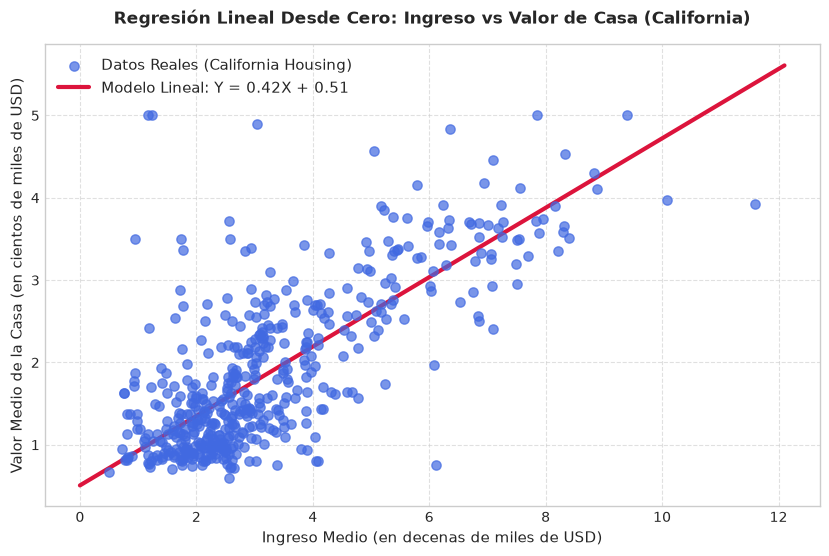

In [4]:
# 4. GRÁFICA DE LOS DATOS Y LA RECTA
plt.figure(figsize=(10, 6))

# Puntos reales de las casas
plt.scatter(X, Y, color='royalblue', s=45, alpha=0.7, label='Datos Reales (California Housing)', zorder=5)

# Línea recta que aprendió el modelo
X_linea = np.linspace(min(X) - 0.5, max(X) + 0.5, 100)
Y_linea = w * X_linea + b
plt.plot(X_linea, Y_linea, color='crimson', linewidth=3, label=f'Modelo Lineal: Y = {w:.2f}X + {b:.2f}')

# Títulos y etiquetas
plt.title('Regresión Lineal Desde Cero: Ingreso vs Valor de Casa (California)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ingreso Medio (en decenas de miles de USD)', fontsize=11)
plt.ylabel('Valor Medio de la Casa (en cientos de miles de USD)', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

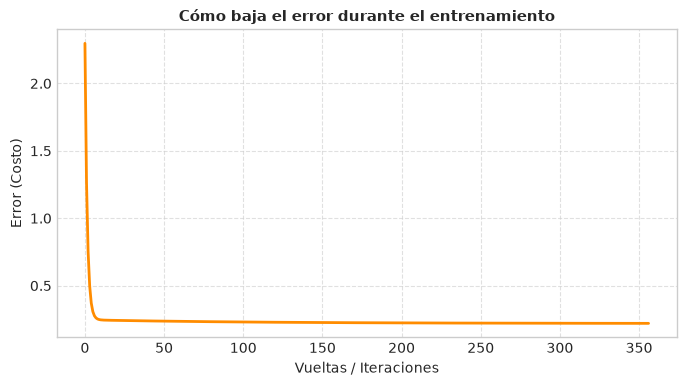

In [5]:
# 5. GRÁFICA DE CÓMO BAJA EL ERROR
plt.figure(figsize=(8, 4))
plt.plot(range(len(historial_costos)), historial_costos, color='darkorange', linewidth=2)
plt.title('Cómo baja el error durante el entrenamiento', fontsize=11, fontweight='bold')
plt.xlabel('Vueltas / Iteraciones', fontsize=10)
plt.ylabel('Error (Costo)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()